# Speeding up the objective function calculation using numba

The objective function is evaluated over and over again and it makes sense to spent some time to make it faster. Here we use the just-in-time compilation option from `numba`.


In [1]:
# --- Tự động lưu mọi hình vẽ ra thư mục figures/ (để chèn vào báo cáo) ---
import os, matplotlib.pyplot as plt
from IPython import get_ipython
os.makedirs("figures", exist_ok=True)
_FIG_PREFIX, _fig_n = "numba", [0]
def _save_open_figs():
    for num in plt.get_fignums():
        fig = plt.figure(num)
        if getattr(fig, "_saved", False): continue
        _fig_n[0] += 1
        fig.savefig(f"figures/{_FIG_PREFIX}_{_fig_n[0]:02d}.png", dpi=150, bbox_inches="tight")
        fig._saved = True
_orig_show = plt.show
def _show(*a, **k):
    _save_open_figs(); return _orig_show(*a, **k)
plt.show = _show
_ip = get_ipython()
if _ip is not None:
    from matplotlib_inline import backend_inline
    try: _ip.events.unregister("post_execute", backend_inline.flush_figures)
    except Exception: pass
    def _flush():
        _save_open_figs(); backend_inline.flush_figures()
    _ip.events.register("post_execute", _flush)


## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Objective function calculation

### Naive $O(n^2)$ Implementation
Naive implementation with nested loops. This is $O(n^2)$.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
import math

In [3]:
def conflicts_naive(board):
    """Calculate the number of conflicts, i.e., the objective function."""
    
    board = np.array(board)
    
    n = len(board)
    val = 0

    # check horizontal (we do not check vertical since the state space is restricted to one queen per col)
    for i in range(n): val += math.comb(np.sum(board == i), 2)
    #print(f"Horizontal value: {val}")
    
    # check for each queen diagonally up and down (only to the right side of the queen)
    for j in range(n):
        q_up = board[j]
        q_down = board[j]
     
        for jj in range(j+1, n):
            q_up -= 1
            q_down += 1
            if board[jj] == q_up: val += 1
            if board[jj] == q_down: val += 1
        #print(f"Value after queen {j}: {val}")
       
    return(val)    

### $O(n)$ Implementation

A better implementation that should be $O(n)$. Idea: 

1. Count how many queens are in each row (no need to check columns) and how many are in each diagonal.
2. Convert the number of $n$ queens in a row (diagonal) into the numbner of pariwise conflicts in $n$ choose 2. We use a faster special case for the `comb()` function to calcualte the conflicts given the number of queens.   

In [4]:
def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    # we have double the diagonals compared to columns!
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

### Compiled $O(n)$ Implementation
We can use just-in-time compilation for the conflicts function. Code provided by Troy McNitt.

In [5]:
from numba import njit

# with jit (cannot use some Python functions like sum and map)
@njit()
def comb2_jit(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

@njit()
def conflicts_jit(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
 
    cnt = [0] * (5 * n)
 
    for i in range(n):
        cnt[board[i]] += 1
        cnt[(n) + (i + board[i])] += 1
        cnt[(3 * n) + (i - board[i] + n)] += 1
 
    conflicts = 0
    for x in cnt:
        conflicts += comb2_jit(x)
 
    return conflicts

# Compare Timing

Compare runtime on 50 random boards of different sizes.

In [6]:
np.random.seed(1234)
def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

In [7]:
import timeit
 
# run it once to force compilation
conflicts_jit(random_board(4))
    
reps = 20
x = []
naive_times = []
linear_times = []
jit_times = []
 
 
for i in [8] + list(range(50, 500, 50)):
    # do reps replications on random boards
    boards = [random_board(i) for _ in range(reps)]
 
    #print(f"Doing: {i}")

    # number = 1 means we only run it once in timeit 
    naive = timeit.timeit(
        lambda: [conflicts_naive(board) for board in boards], number=1
    )
    linear = timeit.timeit(
        lambda: [conflicts(board) for board in boards], number=1
    )
    jit = timeit.timeit(
        lambda: [conflicts_jit(board) for board in boards], number=1
    )

 
    x.append(i)
    naive_times.append(naive)
    linear_times.append(linear)
    jit_times.append(jit)

# average time per board in microseconds
naive_times = np.array(naive_times) / reps * 1e6
linear_times = np.array(linear_times) / reps * 1e6
jit_times = np.array(jit_times) / reps * 1e6

print("Times for 8x8 board in microseconds")
print(f'naive: {naive_times[0]}, linear: {linear_times[0]}, jit: {jit_times[0]}')
 

Times for 8x8 board in microseconds
naive: 39.923849999468075, linear: 7.869099999879835, jit: 0.7195000002013785


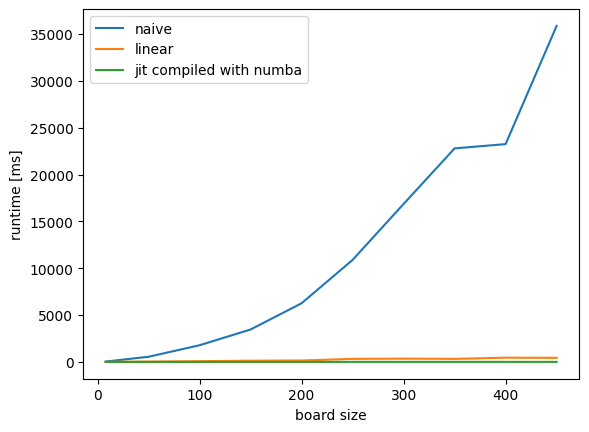

In [8]:
plt.plot(x, naive_times)
plt.plot(x, linear_times)
plt.plot(x, jit_times)
plt.xlabel("board size")
plt.ylabel("runtime [ms]")
plt.legend(["naive", "linear", "jit compiled with numba"])
plt.show()

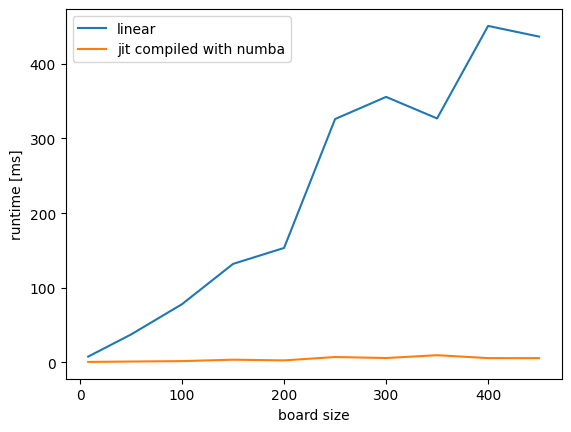

In [9]:
plt.plot(x, linear_times)
plt.plot(x, jit_times)
plt.xlabel("board size")
plt.ylabel("runtime [ms]")
plt.legend(["linear", "jit compiled with numba"])
plt.show()

## Bài 6 – Giải thích và nhận xét
**Đếm theo hàng/đường chéo và C(k,2).** Hai quân hậu xung đột nếu cùng hàng, cùng đường chéo “/” (i + hàng không đổi) hoặc cùng đường chéo “\\” (i − hàng không đổi). Thay vì so sánh từng cặp (n(n−1)/2 cặp), ta duyệt n quân hậu **một lần**, tăng bộ đếm của hàng và hai đường chéo mà nó thuộc về (`horizontal_cnt`, `diagonal1_cnt[i+row]`, `diagonal2_cnt[i-row+n]`). Nếu một hàng/đường chéo có *k* quân hậu thì chúng tạo ra C(k,2) = k(k−1)/2 cặp xung đột, nên

  f(board) = Σ C(k, 2) trên mọi hàng và mọi đường chéo.

**Độ phức tạp.** `conflicts_naive` có hai vòng lặp lồng nhau ⇒ O(n²); `conflicts` chỉ một vòng lặp tăng bộ đếm + một lượt tính tổng trên 5n bộ đếm ⇒ **O(n)**.

**Numba JIT.** `conflicts_jit` có cùng độ phức tạp O(n) nhưng được biên dịch sang mã máy nên hằng số nhỏ hơn (nhanh hơn ~10 lần ở bàn 8×8: ~0.6 µs so với ~7 µs). Đây là khác biệt giữa *độ phức tạp thuật toán* (cách thời gian tăng theo n – naive O(n²) so với O(n)) và *lợi ích biên dịch* (giảm hằng số, không đổi bậc tăng trưởng). Vì vậy trên đồ thị, đường `jit` và `linear` song song nhau (đều tuyến tính) còn `naive` cong lên.

**Vì sao phải gọi `conflicts_jit()` một lần trước khi đo?** Lần gọi đầu tiên Numba mất thời gian biên dịch (hàng trăm ms) – lớn hơn nhiều so với thời gian chạy thật (µs). Nếu không “khởi động” trước, thời gian biên dịch sẽ bị tính vào phép đo và làm sai lệch kết quả so sánh; notebook đã gọi `conflicts_jit(random_board(4))` một lần trước khi đo.